In [1]:
import numpy as np
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import os
import glob
from contextlib import contextmanager
import joblib as job

In [2]:
if "get_ipython" not in globals() or "get_ipython" in globals() and get_ipython().__class__.__name__ == "TerminalInteractiveShell":
    matplotlib.use("Agg")
    plt.rcParams.update({"figure.dpi": 200})

def plot(figsize=(6.4, 4.8), **kwargs):
    plt.gcf().set_size_inches(*figsize)
    if "get_ipython" not in globals() or get_ipython().__class__.__name__ == "TerminalInteractiveShell":
        plt.savefig("a.png", **kwargs)
        plt.clf()
        plt.cla()
    else:
        plt.show()
    plt.close()

def dbg(x):
    print(x)
    return x

# https://stackoverflow.com/a/17511341
def ceildiv(a, b):
    return -(a // -b)

def nplots(n, cols, tight=None, figsize=None):
    rows = ceildiv(n, cols)
    figsize=figsize if figsize is not None else (6 * cols, 4 * rows)

    fig, axes = plt.subplots(rows, cols, figsize=figsize)

    for i, ax in enumerate(axes.flatten() if n != 1 else [axes]):
        if i >= n:
            fig.delaxes(ax)
            continue

        yield i, ax

    if tight != False and (n != 1 or tight == True):
        plt.tight_layout()

    plot(figsize=figsize)

@contextmanager
def oneplot(tight=None, figsize=None):
    for _, ax in nplots(1, 1, tight=tight, figsize=figsize):
        yield ax

sample_prev_df=None
sample_prev_n=None
sample_ret=None

def sample(df, n=400_000):
    global sample_prev_df
    global sample_prev_n
    global sample_ret

    if sample_prev_df is df and n == sample_prev_n:
        return sample_ret

    sample_ret = None
    sample_prev_df = df
    sample_prev_n = n

    return (sample_ret := df.sample(n, random_state=217, replace=False))

In [3]:
def load_clean(pat):
    return pd.concat([
        pd.read_csv(
            dbg(name),
            dtype=dict(
                VendorID=int,
                passenger_count=float,
                trip_distance=float,
                RatecodeID="category",
                # has NAs, but we're unlikely to use this column so
                # don't drop it
                store_and_fwd_flag="boolean",
                PULocationID="category",
                DOLocationID="category",
                payment_type=int,
                fare_amount=float,
                extra=float,
                mta_tax=float,
                tip_amount=float,
                tolls_amount=float,
                improvement_surcharge=float,
                total_amount=float,
                congestion_surcharge=float,
                Airport_fee=float,
                duration_hours=float,
                avg_speed_mph=float,
                fare_per_hour=float,
            ),
            parse_dates=[
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
            ],
        )
        for name in sorted(glob.glob(f"../dataset-clean/{pat}"))
    ], ignore_index=True)

In [4]:
rides_train = load_clean("train_*")
rides_test = load_clean("test_*")
# rides_sample = load_clean("sample_*")

../dataset-clean/train_00.csv
../dataset-clean/train_01.csv
../dataset-clean/train_02.csv
../dataset-clean/train_03.csv
../dataset-clean/train_04.csv
../dataset-clean/train_05.csv
../dataset-clean/train_06.csv
../dataset-clean/train_07.csv
../dataset-clean/train_08.csv
../dataset-clean/train_09.csv
../dataset-clean/train_10.csv
../dataset-clean/train_11.csv
../dataset-clean/train_12.csv
../dataset-clean/train_13.csv
../dataset-clean/train_14.csv
../dataset-clean/test_00.csv
../dataset-clean/test_01.csv
../dataset-clean/test_02.csv
../dataset-clean/test_03.csv
../dataset-clean/test_04.csv


In [5]:
def group_zone_hour(
    df,
    aggs,
):
    """
    Aggregrate trips into zone-hour statistics

    df : pd.DataFrame
        Trip-level dataframe
    aggs : function, str, list, dict or None
        Argument to pd.DataFrameGroupBy.agg, specify which columsn and
        how aggregation should be done

    Returns:
    pd.DataFrame
        Dataframe with zone-hour and aggregated values
    """
    378798
    586920

    df = (
        df
            .groupby(["PULocationID", "pickup_hour"], observed=True)
            .agg(aggs)
            .reset_index()
    )
    # flaten column names
    df.columns = [(f"cur_{x}_{y}" if y else x) for (x, y) in df.columns]

    return df

def with_lags(
    df,
    feature,
    agg,
    window="2h",
    offsets=["1h"],
):
    agged = df.rename(
        columns=lambda x: x.removeprefix("cur_") if isinstance(x, str) else x,
    ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
        window,
        on="pickup_hour",
    ).agg(agg)

    for offset in offsets:
        df = pd.merge(
            df,
            agged.assign(
                pickup_hour=agged["pickup_hour"] +
                    (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
            ).rename(
                columns=lambda x:
                    f"lag_{feature}-{agg}-{window}-{offset}" if x not in ["PULocationID", "pickup_hour"] else x,
            ),
            how="left",
            on=["PULocationID", "pickup_hour"],
        )

    return df

In [6]:
demand_lags = [
    ("count", "mean", "1h", ["23h", "24h", "48h"]),
    ("count", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_sum", "mean", "1h", ["23h", "24h", "48h"]),
    ("duration_hours_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_sum", "mean", "1h", ["23h", "24h", "48h"]),
    ("trip_distance_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("avg_speed_mph_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("ratecode_is_1_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_2_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_3_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_4_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_5_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_6_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_99_mean", "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_1_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_2_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_3_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_4_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_5_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_6_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_99_mean", "mean", "1d", ["1d", "2d"]),

    ("do_is_upper_east_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_midtown_mean"   , "mean", "2h", ["23h", "24h"]),
    ("do_is_financial_mean" , "mean", "2h", ["23h", "24h"]),
    ("do_is_turtle_bay_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_north_mean"     , "mean", "2h", ["23h", "24h"]),
    ("do_is_upper_east_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_midtown_mean"   , "mean", "1d", ["1d", "2d"]),
    ("do_is_financial_mean" , "mean", "1d", ["1d", "2d"]),
    ("do_is_turtle_bay_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_north_mean"     , "mean", "1d", ["1d", "2d"]),
]

revenue_lags = [
    ("fare_amount_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("fare_amount_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("duration_hours_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("trip_distance_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("avg_speed_mph_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("ratecode_is_1_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_2_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_3_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_4_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_5_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_6_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_99_mean", "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_1_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_2_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_3_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_4_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_5_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_6_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_99_mean", "mean", "1d", ["1d", "2d"]),

    ("do_is_upper_east_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_midtown_mean"   , "mean", "2h", ["23h", "24h"]),
    ("do_is_financial_mean" , "mean", "2h", ["23h", "24h"]),
    ("do_is_turtle_bay_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_north_mean"     , "mean", "2h", ["23h", "24h"]),
    ("do_is_upper_east_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_midtown_mean"   , "mean", "1d", ["1d", "2d"]),
    ("do_is_financial_mean" , "mean", "1d", ["1d", "2d"]),
    ("do_is_turtle_bay_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_north_mean"     , "mean", "1d", ["1d", "2d"]),
]

In [7]:
numerical_pipeline = sk.pipeline.Pipeline([
    ("imputer", sk.impute.SimpleImputer(strategy="mean")),
    ("scaler", sk.preprocessing.QuantileTransformer()),
])

full_pipeline = sk.compose.ColumnTransformer([
    (
        "num",
        numerical_pipeline,
        sk.compose.make_column_selector(dtype_include=np.float64),
    ),
    (
        "cat_ohe",
        sk.preprocessing.OneHotEncoder(
            categories=[
                list(rides_train["PULocationID"].unique()),
                list(range(24)),
            ]
        ),
        ["PULocationID", "pickup_hour_of_day"],
    ),
], remainder="drop")

In [8]:
zone_upper_east = [str(x) for x in [236, 237, 141, 142, 262]]
zone_midtown = [str(x) for x in [161, 162, 163]]
zone_financial = [str(x) for x in [12, 88, 87, 261]]
zone_turtle_bay = [str(x) for x in [162, 229]]
zone_north = [str(x) for x in [42, 116, 127, 243, 255]]

def build_xy(rides_clean, y_col, lags):
    rides_feat = rides_clean.assign(
        pickup_hour = lambda x: x["tpep_pickup_datetime"].dt.floor("1h"),
        pickup_hour_of_day = lambda x:
            x["tpep_pickup_datetime"].dt.hour +
            (x["tpep_pickup_datetime"].dt.minute / 60),
        # monday = 0
        pickup_day_of_week = lambda x:
            (x["tpep_pickup_datetime"].dt.day_of_week) +
            (x["tpep_pickup_datetime"].dt.hour / 24) +
            (x["tpep_pickup_datetime"].dt.minute / (60 * 24)),
        ratecode_is_airport = lambda x: x["RatecodeID"].isin(["2", "3"]),
        # total amount includes extra surcharges/fees => stronger patterns tip %
        tip_ratio = lambda x: (x["tip_amount"] / (x["total_amount"] - x["tip_amount"])).fillna(0),
    )

    rides_hour = group_zone_hour(
        pd.concat(
            [
                rides_feat,
                pd.DataFrame({
                    f"ratecode_is_{n}": rides_feat["RatecodeID"] == n
                    for n in [1, 2, 3, 4, 5, 6, 99]
                }),
                pd.DataFrame(dict(
                    do_is_upper_east=rides_feat["DOLocationID"].isin(zone_upper_east),
                    do_is_midtown=rides_feat["DOLocationID"].isin(zone_midtown),
                    do_is_financial=rides_feat["DOLocationID"].isin(zone_financial),
                    do_is_turtle_bay=rides_feat["DOLocationID"].isin(zone_turtle_bay),
                    do_is_north=rides_feat["DOLocationID"].isin(zone_north),
                ))
            ],
            axis=1,
        ),
        dict(
            passenger_count="mean",
            trip_distance=["sum", "mean"],
            # amount without tips or fees
            fare_amount=["sum", "mean"],
            # the following are somewhat fixed fees so the means
            # are losely counts of rides where the fee is charged
            # not much info intrinsically but maybe a patern?
            mta_tax="mean",
            tolls_amount="mean",
            improvement_surcharge="mean",
            congestion_surcharge="mean",
            Airport_fee="mean",
            # total amount including tips and fees
            # * in our case these are "noise" when making predictions
            # * if we really wanted to be vultures we might look at tips
            #   as an indicator of routes where we could charge more
            total_amount=["sum", "mean"],
            tip_amount="mean",
            tip_ratio="mean",
            # probably correlated with demand
            # * count used in this column arbitrarily
            duration_hours=["count", "sum", "mean"],
            avg_speed_mph="mean",
            fare_per_hour="mean",
            ratecode_is_airport=["mean", "count"],

            ratecode_is_1="mean",
            ratecode_is_2="mean",
            ratecode_is_3="mean",
            ratecode_is_4="mean",
            ratecode_is_5="mean",
            ratecode_is_6="mean",
            ratecode_is_99="mean",

            do_is_upper_east="mean",
            do_is_midtown="mean",
            do_is_financial="mean",
            do_is_turtle_bay="mean",
            do_is_north="mean",
        ),
    ).assign(
        pickup_hour_of_day=lambda x: x["pickup_hour"].dt.hour,
    ).rename(
        columns=dict(
            cur_duration_hours_count="cur_count",
        )
    )

    X = rides_hour

    for feat, agg, window, offsets in lags:
        X = with_lags(
            X,
            feat,
            agg,
            window=window,
            offsets=offsets,
        )

    index_cols = [
        "PULocationID",
        "pickup_hour",
        "pickup_hour_of_day",
    ]

    y = X[y_col]
    X = X.drop(columns=[
        x
        for x in X.columns
        if x.startswith("cur_")
    ])

    assert all((x.startswith("lag_") or x in index_cols) for x in X.columns)

    return X, y

In [9]:
def eval_final(
    rides_clean_train,
    rides_clean_test,
    target,
    lags,
    model,
):
    pre = sk.clone(full_pipeline)

    print("building sets")

    X, y = build_xy(rides_clean_train, target, lags)
    X = pre.fit_transform(X, y)
    X = X.toarray() if hasattr(X, "toarray") else X

    X_test, y_test = build_xy(rides_clean_test, target, lags)
    X_test_keys = X_test[["PULocationID", "pickup_hour"]]
    X_test = pre.transform(X_test)
    X_test = X_test.toarray() if hasattr(X, "toarray") else X_test

    print("train set size", X.shape)
    print("test set size", X_test.shape)
    print("starting fit")

    model.fit(X, y)

    print("finished fit")

    print("\n" * 5)

    print("=")
    print("==")
    print("===")
    print("==== fit complete ====")
    print("===")
    print("==")
    print("=")

    y_pred = model.predict(X)
    y_test_pred = model.predict(X_test)

    imp = sk.inspection.permutation_importance(
        model,
        X_test,
        y_test,
        scoring="neg_mean_squared_error",
        n_repeats=5,
        random_state=2718,
        n_jobs=-1,
    )

    feature_names = pre.get_feature_names_out()

    imp_df = pd.DataFrame({
        "feature": feature_names,
        "importance_mean": imp.importances_mean,
        "importance_std": imp.importances_std,
    }).sort_values("importance_mean", ascending=True).reset_index(drop=True)

    print("importance complete")

    metrics = pd.DataFrame(
        {
            "mse"  : [
                sk.metrics.mean_squared_error(y, y_pred),
                sk.metrics.mean_squared_error(y_test, y_test_pred),
            ],
            "rmse" : [
                sk.metrics.root_mean_squared_error(y, y_pred),
                sk.metrics.root_mean_squared_error(y_test, y_test_pred),
            ],
            "mae" : [
                sk.metrics.mean_absolute_error(y, y_pred),
                sk.metrics.mean_absolute_error(y_test, y_test_pred),
            ],
            "r2"   : [
                sk.metrics.r2_score(y, y_pred),
                sk.metrics.r2_score(y_test, y_test_pred),
            ],
        },
        index = ["train", "test"],
    )

    return model, X_test_keys, y_test, y_test_pred, imp_df, metrics

In [10]:
model_trained_demand, X_test_keys_demand, y_test_demand, y_test_pred_demand, imp, metrics_demand = eval_final(
    rides_train,
    rides_test,
    "cur_count",
    demand_lags,
    sk.neural_network.MLPRegressor(
        random_state=2718,
        verbose=10,
        **{
            'activation': 'tanh',
            'alpha': 0.0001,
            'hidden_layer_sizes': (25, 25, 10, 15),
            'learning_rate_init': 0.001,
        },
    ),
)

print(metrics_demand)

building sets
train set size (388101, 174)
test set size (116185, 174)
starting fit
Iteration 1, loss = 4801.57631707
Iteration 2, loss = 3524.04937355
Iteration 3, loss = 2661.71591394
Iteration 4, loss = 2041.24681134
Iteration 5, loss = 1591.31541474
Iteration 6, loss = 1265.16603877
Iteration 7, loss = 1031.47080966
Iteration 8, loss = 867.31929600
Iteration 9, loss = 745.78888623
Iteration 10, loss = 654.11195981
Iteration 11, loss = 585.58474837
Iteration 12, loss = 535.40439034
Iteration 13, loss = 497.79841269
Iteration 14, loss = 470.55137109
Iteration 15, loss = 449.19896027
Iteration 16, loss = 433.79666374
Iteration 17, loss = 422.40641773
Iteration 18, loss = 411.85172009
Iteration 19, loss = 401.56707369
Iteration 20, loss = 395.75998379
Iteration 21, loss = 390.04947548
Iteration 22, loss = 382.99738036
Iteration 23, loss = 381.67010650
Iteration 24, loss = 377.61527634
Iteration 25, loss = 373.29348543
Iteration 26, loss = 369.95522098
Iteration 27, loss = 368.23249894


/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


importance complete
              mse       rmse        mae        r2
train  597.915676  24.452314  13.715798  0.918796
test   973.528373  31.201416  16.747439  0.880168


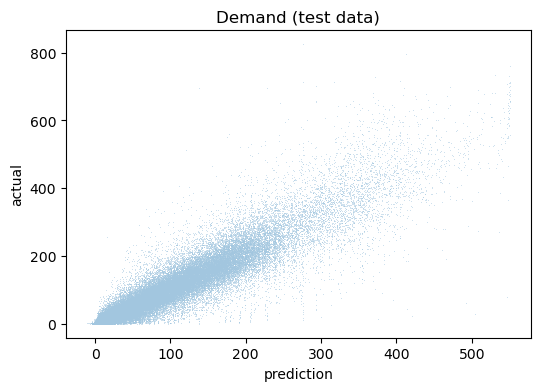

In [11]:
with oneplot() as ax:
    sns.scatterplot(
        ax=ax,
        x=y_test_pred_demand,
        y=y_test_demand,
        s=0.2,
        linewidth=0,
    ),
    ax.set_xlabel("prediction")
    ax.set_ylabel("actual")
    ax.set_title("Demand (test data)")

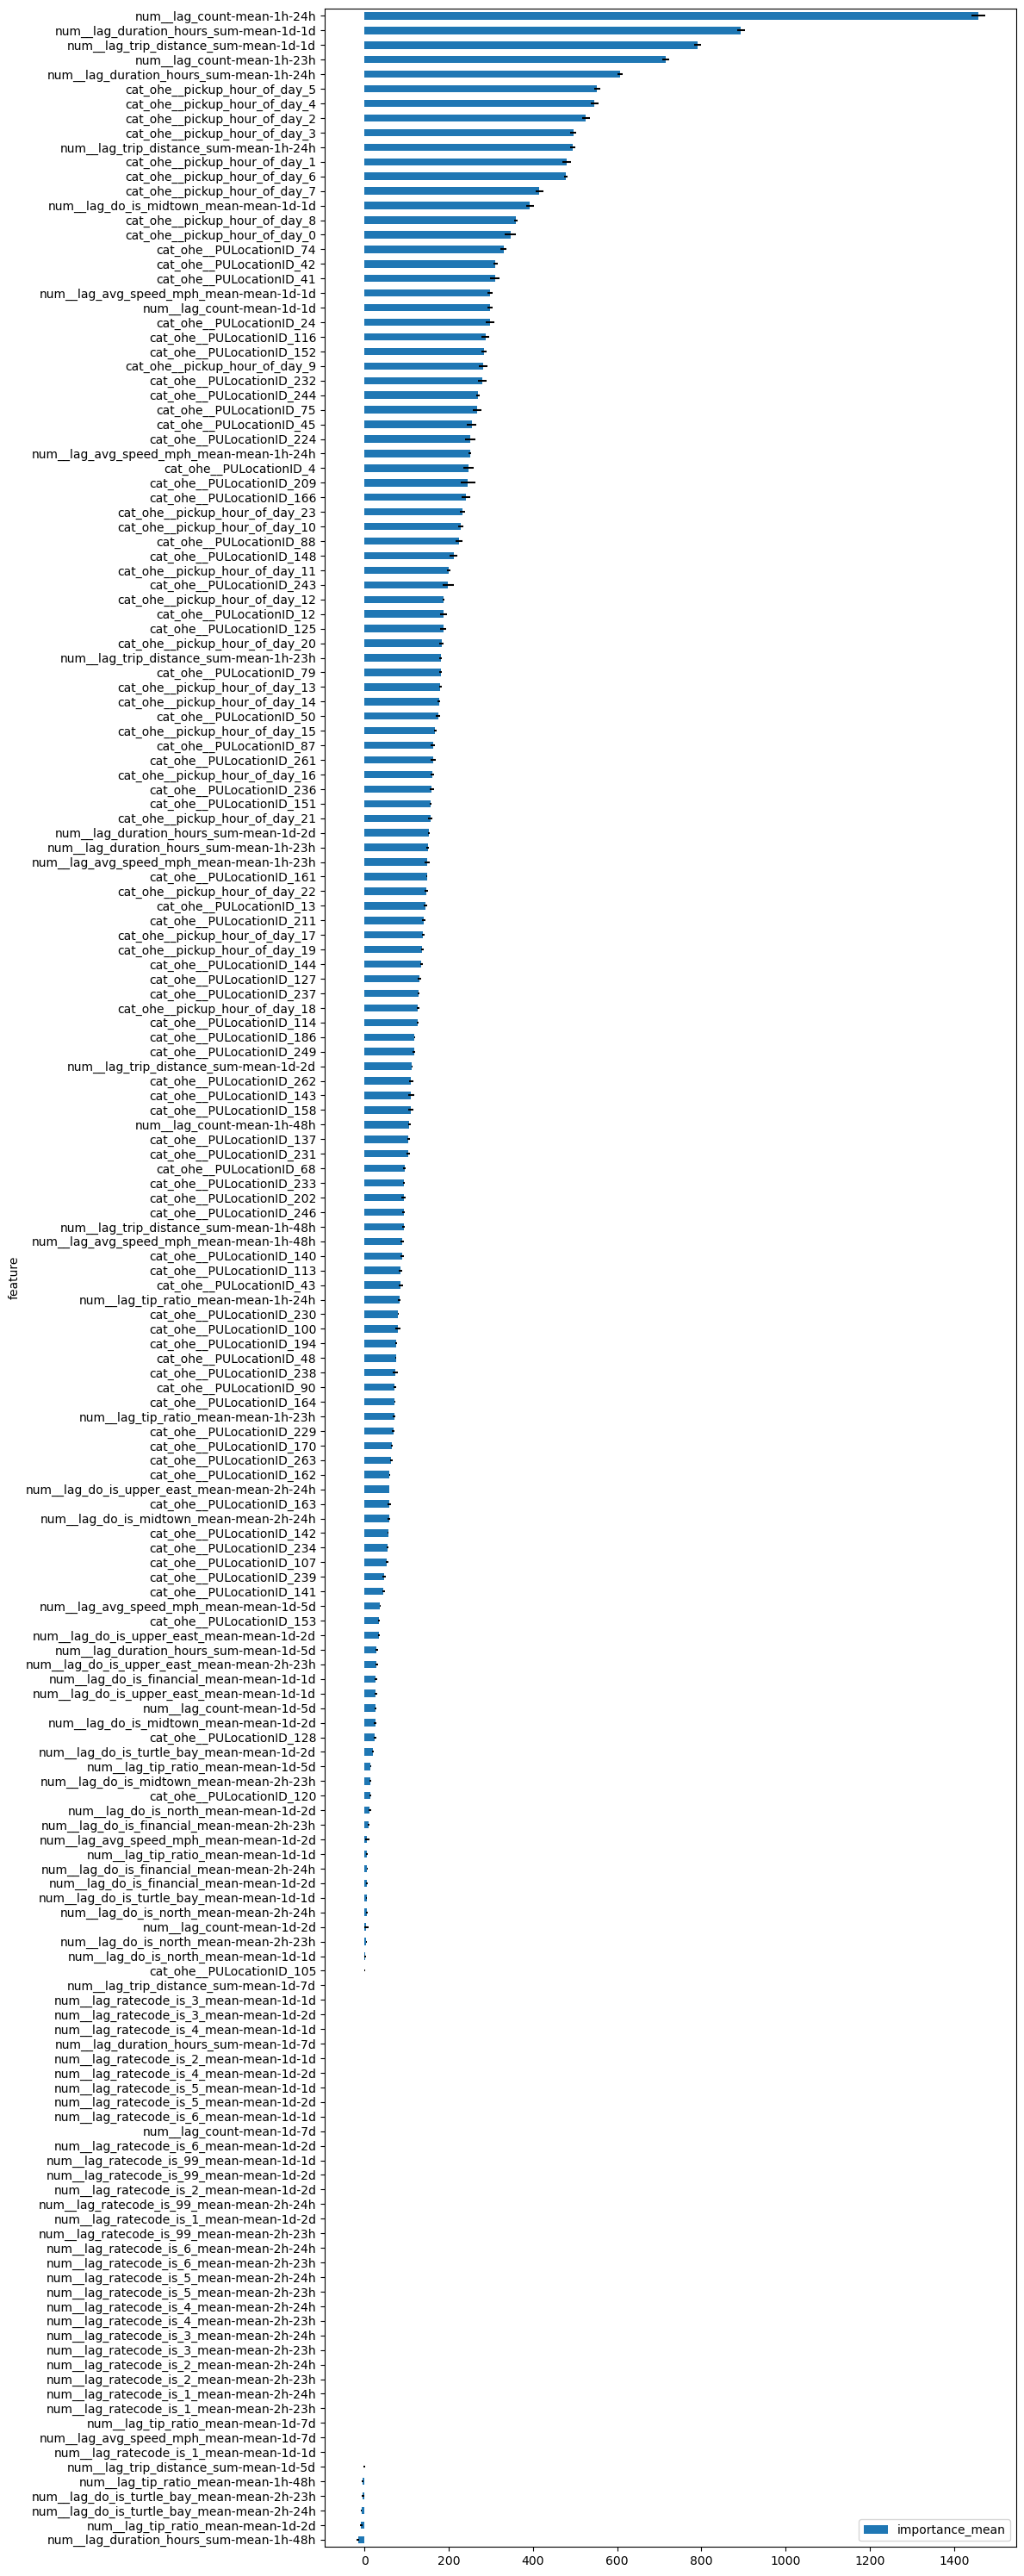

In [12]:
with oneplot(figsize=(12, 30), tight=True) as ax:
    imp.plot.barh(
        ax=ax,
        x="feature",
        y="importance_mean",
        xerr="importance_std",
    )

In [13]:
model_trained_revenue, X_test_keys_revenue, y_test_revenue, y_test_pred_revenue, imp_revenue, metrics = eval_final(
    rides_train,
    rides_test,
    "cur_fare_amount_mean",
    revenue_lags,
    sk.ensemble.HistGradientBoostingRegressor(
        random_state=2718,
        verbose=10,
        **{
            'learning_rate': 0.1,
            'max_depth': None,
            'max_leaf_nodes': 63,
            'min_samples_leaf': 40,
        },
    ),
)

print(metrics)

building sets
train set size (388101, 174)
test set size (116185, 174)
starting fit
Binning 0.486 GB of training data: 0.477 s
Binning 0.054 GB of validation data: 0.043 s
Fitting gradient boosted rounds:
[1/100] 1 tree, 63 leaves, max depth = 22, train loss: 23.22017, val loss: 22.50780, in 0.144s
[2/100] 1 tree, 63 leaves, max depth = 23, train loss: 22.10923, val loss: 21.40890, in 0.140s
[3/100] 1 tree, 63 leaves, max depth = 22, train loss: 21.18294, val loss: 20.49461, in 0.149s
[4/100] 1 tree, 63 leaves, max depth = 24, train loss: 20.43226, val loss: 19.76483, in 0.136s
[5/100] 1 tree, 63 leaves, max depth = 22, train loss: 19.80719, val loss: 19.14474, in 0.137s
[6/100] 1 tree, 63 leaves, max depth = 19, train loss: 19.28195, val loss: 18.63358, in 0.141s
[7/100] 1 tree, 63 leaves, max depth = 26, train loss: 18.82681, val loss: 18.19597, in 0.139s
[8/100] 1 tree, 63 leaves, max depth = 17, train loss: 18.44504, val loss: 17.82317, in 0.141s
[9/100] 1 tree, 63 leaves, max dept

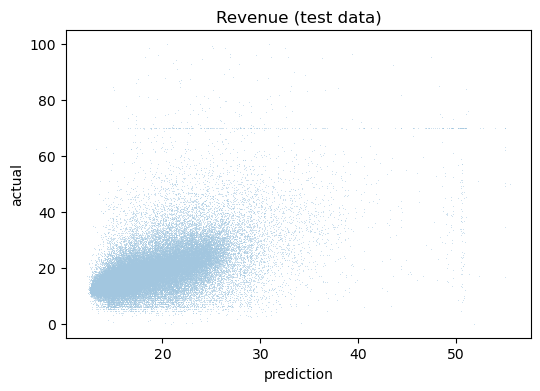

In [14]:
with oneplot() as ax:
    sns.scatterplot(
        ax=ax,
        x=y_test_pred_revenue,
        y=y_test_revenue,
        s=0.2,
        linewidth=0,
    ),
    ax.set_xlabel("prediction")
    ax.set_ylabel("actual")
    ax.set_title("Revenue (test data)")

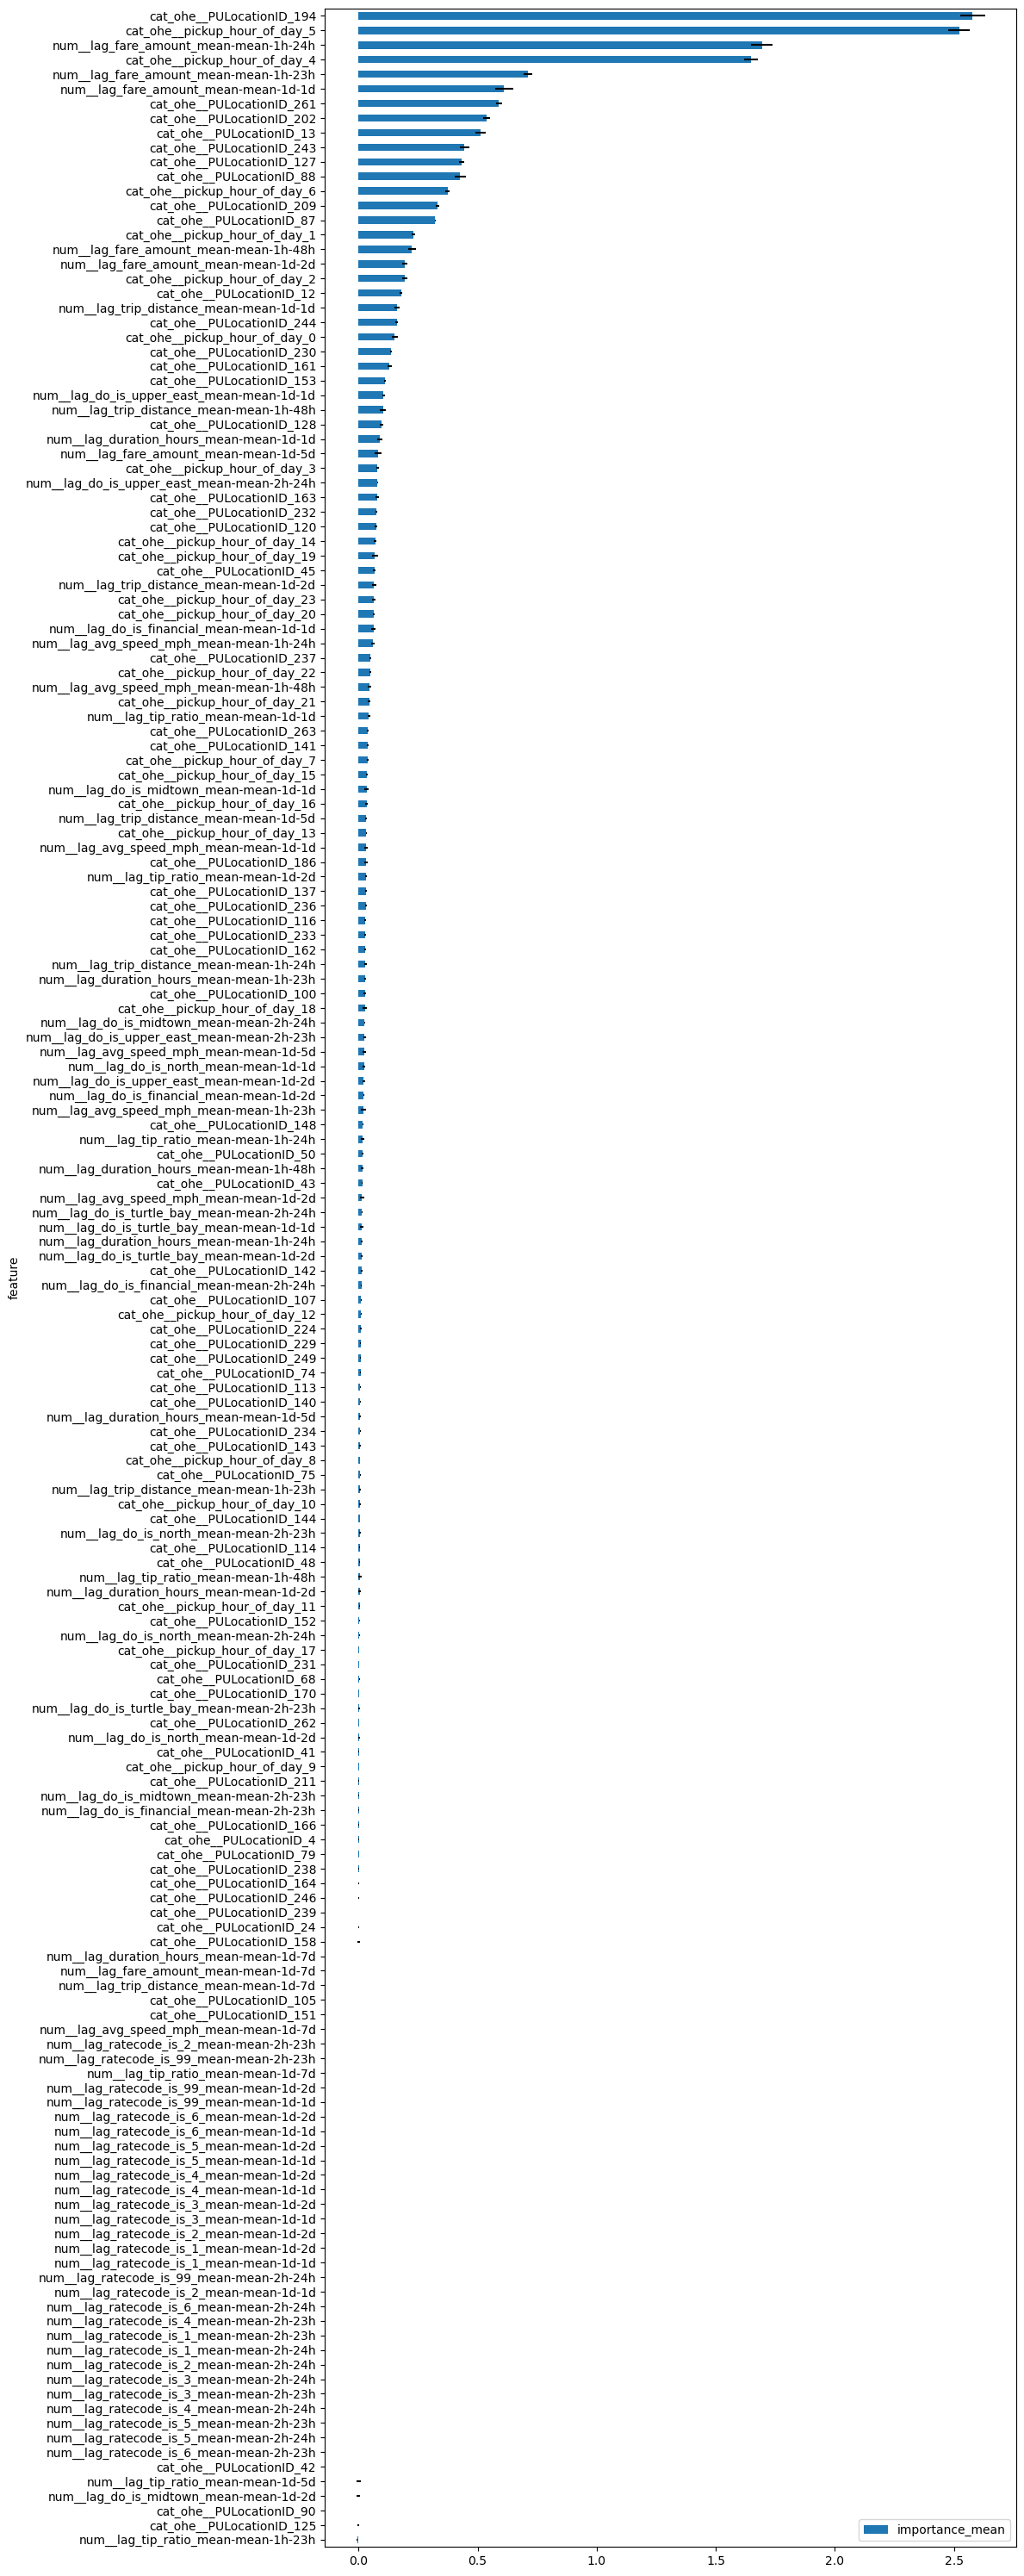

In [15]:
with oneplot(figsize=(12, 30), tight=True) as ax:
    imp_revenue.plot.barh(
        ax=ax,
        x="feature",
        y="importance_mean",
        xerr="importance_std",
    )

In [16]:
predictions = pd.merge(
    pd.concat([X_test_keys_demand, pd.Series(y_test_pred_demand, name="pred_ride_count")], axis="columns"),
    pd.concat([X_test_keys_revenue, pd.Series(y_test_pred_revenue, name="pred_mean_fare_amount")], axis="columns"),
    on=["PULocationID", "pickup_hour"],
).assign(
    pred_revenue=lambda x: x["pred_ride_count"] * x["pred_mean_fare_amount"],
)
predictions

,PULocationID,pickup_hour,pred_ride_count,pred_mean_fare_amount,pred_revenue
0,100,2024-01-14 00:00:00,62.538771,15.157890,947.955831
1,100,2024-01-14 01:00:00,34.505696,14.566488,502.626815
2,100,2024-01-14 02:00:00,21.042946,15.015035,315.960560
3,100,2024-01-14 03:00:00,18.094109,17.296451,312.963862
4,100,2024-01-14 04:00:00,14.610512,21.484055,313.893053
...,...,...,...,...,...
116180,90,2024-12-20 19:00:00,133.772615,15.206423,2034.203021
116181,90,2024-12-20 20:00:00,118.811328,15.964667,1896.783331
116182,90,2024-12-20 21:00:00,125.963589,15.945670,2008.573753
116183,90,2024-12-20 22:00:00,108.311053,16.476986,1784.639665


In [17]:
predictions.to_csv("../predictions.csv", index=False)